In [1]:
import pandas as pd

df = pd.read_csv('customer-dataset.csv')
df

,Unnamed: 0,flags,instruction,category,intent,response
0,0,B,question about cancelling order {{Order Number}},ORDER,cancel_order,I've understood you have a question regarding ...
1,1,BQZ,i have a question about cancelling oorder {{Or...,ORDER,cancel_order,I've been informed that you have a question ab...
2,2,BLQZ,i need help cancelling puchase {{Order Number}},ORDER,cancel_order,I can sense that you're seeking assistance wit...
3,3,BL,I need to cancel purchase {{Order Number}},ORDER,cancel_order,I understood that you need assistance with can...
4,4,BCELN,"I cannot afford this order, cancel purchase {{...",ORDER,cancel_order,I'm sensitive to the fact that you're facing f...
...,...,...,...,...,...,...
26867,26867,BL,I am waiting for a rebate of {{Refund Amount}}...,REFUND,track_refund,Thank you for sharing your situation regarding...
26868,26868,BIL,how to see if there is anything wrong with my ...,REFUND,track_refund,Ensuring the accuracy of your restitution is o...
26869,26869,BLQZ,I'm waiting for a reimbjrsement of {{Currency ...,REFUND,track_refund,"Firstly, I genuinely understand the importance..."
26870,26870,BL,I don't know what to do to see my reimbursemen...,REFUND,track_refund,I've understood you're unsure about how to che...


In [ ]:
intents = set(df['intent'])
print(intents)
print(len(intents))

{'delivery_period', 'recover_password', 'review', 'check_payment_methods', 'contact_customer_service', 'payment_issue', 'registration_problems', 'check_cancellation_fee', 'change_shipping_address', 'track_order', 'contact_human_agent', 'set_up_shipping_address', 'get_invoice', 'create_account', 'check_refund_policy', 'get_refund', 'switch_account', 'track_refund', 'delete_account', 'delivery_options', 'complaint', 'place_order', 'newsletter_subscription', 'cancel_order', 'check_invoice', 'edit_account', 'change_order'}
27


In [ ]:
categories = set(df['category'])
print(categories)
print(len(categories))

{'SHIPPING', 'ACCOUNT', 'CANCEL', 'FEEDBACK', 'REFUND', 'DELIVERY', 'INVOICE', 'PAYMENT', 'SUBSCRIPTION', 'ORDER', 'CONTACT'}
11


In [ ]:
from llm import get_llm

# llm = get_llm("deepseek")
llm = get_llm("qwen/qwen3.8-27b")
response = llm.invoke([
    {
        "role": "system",
        "content": "an ai agent bot"
    },
    {
        "role": "user",
        "content": "what is CoALA framework"
    }
]
)

response

AIMessage(content='The **CoALA** framework stands for **Cognitive Architectures for Language Agents**. It is a conceptual framework proposed by researchers (notably from Stanford University, including researchers like Shunyu Yao, Jeffrey Zhao, and others) to provide a unified, structured way to understand, design, and evaluate **LLM-based agents**.\n\n### Core Idea\nCoALA treats an LLM agent as a **cognitive system** with distinct components, analogous to how human cognition is modeled in cognitive science. It breaks down an agent into four main modules:\n\n1. **Memory**\n2. **Action Space**\n3. **Decision-Making Module**\n4. **Perception Module**\n\nThis framework helps researchers and developers think systematically about how agents process information, make decisions, and interact with their environment.\n\n---\n\n### The Four Components of CoALA\n\n#### 1. Memory\nMemory is divided into two types:\n- **Short-term Memory (STM):**\n  - Typically implemented as the **context window** 

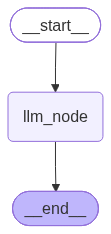

In [30]:
import string
from typing import Annotated
from pydantic import BaseModel, Field
from langgraph.graph import END, START, MessagesState, StateGraph, add_messages
from langchain_core.messages import (
    AIMessage,
    AnyMessage,
    HumanMessage,
    SystemMessage,
)

class CustomState(BaseModel):
    messages:Annotated[list[AnyMessage], add_messages]= Field(default_factory=list, description= "Messages history")
    query: str = Field(default="",description = "query from user")

def llm_node(state: CustomState)-> dict:
    messages = state.messages

    if(not messages):
        messages.append(SystemMessage("you AI tool!"))

    text = ""

    while(text != "exit"):   
        text  = input("enter message")
        messages.append(HumanMessage(text))

        llm = get_llm("qwen/qwen3.8-27b")
        response = llm.invoke(messages)
        print(response)

        messages.append(response)

    return  {
        "messages" : messages
    }

graph = StateGraph(CustomState)
graph.add_node("llm_node", llm_node)
graph.add_edge(START,"llm_node")
graph.add_edge("llm_node",END)
agent = graph.compile()
agent    

In [31]:
state = CustomState(query ="hey what is coala framework")
result = agent.invoke(state)
result

content='The term **"Coala"** is not a standard, widely recognized term in general English, science, or technology. However, depending on the context, it could refer to one of the following:\n\n### 1. **A Misspelling or Variation of "Koala"**\n   - The most likely possibility is that you meant **koala**, the marsupial native to Australia.\n   - "Coala" is a common phonetic misspelling of "koala."\n\n### 2. **A Brand, Product, or Company Name**\n   - **Coala** may be the name of a specific brand, startup, app, or product. For example:\n     - There are small businesses, eco-friendly product lines, or tech startups named "Coala" (e.g., related to sustainability, pets, or software).\n     - Check if you encountered this term in a specific industry (e.g., fashion, tech, or consumer goods).\n\n### 3. **A Username or Online Handle**\n   - "Coala" is a popular username or nickname on social media platforms, gaming communities, or forums.\n\n### 4. **A Local or Niche Term**\n   - In some regio

{'messages': [SystemMessage(content='you AI tool!', additional_kwargs={}, response_metadata={}, id='1c3bc100-b23f-41a5-b995-ecc8343168ab'),
  HumanMessage(content='what is coala', additional_kwargs={}, response_metadata={}, id='bb8a34ce-a436-41df-b27d-940f856b4099'),
  AIMessage(content='The term **"Coala"** is not a standard, widely recognized term in general English, science, or technology. However, depending on the context, it could refer to one of the following:\n\n### 1. **A Misspelling or Variation of "Koala"**\n   - The most likely possibility is that you meant **koala**, the marsupial native to Australia.\n   - "Coala" is a common phonetic misspelling of "koala."\n\n### 2. **A Brand, Product, or Company Name**\n   - **Coala** may be the name of a specific brand, startup, app, or product. For example:\n     - There are small businesses, eco-friendly product lines, or tech startups named "Coala" (e.g., related to sustainability, pets, or software).\n     - Check if you encountere

In [25]:
state.query= "what about CoALA in Agentic AI?"
result = agent.invoke(state)
result

{'messages': [SystemMessage(content='you AI tool!', additional_kwargs={}, response_metadata={}, id='350a8cfc-575b-4abd-8190-f44100456e38'),
  HumanMessage(content='what about CoALA in Agentic AI?', additional_kwargs={}, response_metadata={}, id='6840809c-0e90-4624-b723-4f1ca3dc2fdf'),
  AIMessage(content='**CoALA** stands for **Cognitive Architectures for Language Agents**. It is a foundational framework proposed by researchers at Princeton University (Shunyu Yao, Jeffrey Zhao, Dian Yu, et al.) in 2023.\n\nIt provides a **unified conceptual framework** for understanding, designing, and evaluating **Agentic AI systems** (LLM-based agents). Before CoALA, many agent frameworks were ad hoc; CoALA gives them a structured "blueprint" based on cognitive science.\n\n---\n\n### 🧠 Core Idea\nCoALA models an LLM agent as a **cognitive system** with four main components:\n1. **Memory**\n2. **Action Space**\n3. **Decision-Making Module**\n4. **Feedback Loop**\n\nIt draws inspiration from classic co

In [1]:
from skills_manager import SkillsManager

sm = SkillsManager()
print(sm.generate_first_level_prompt())


## Skills System

You have access to a skills library that provides specialized capabilities and domain knowledge.

Skills Location: skills

**Available Skills:**

- **arxiv-search**: Search the arXiv preprint repository for research papers. Use when the user asks about academic papers, recent research, or scientific literature.
  -> Read `skills\arxiv-search\SKILL.md` for full instructions
- **langgraph-docs**: Use this skill for requests related to LangGraph in order to fetch relevant documentation to provide accurate, up-to-date guidance.
  -> Read `skills\langgraph-docs\SKILL.md` for full instructions
- **tickets-internal-system**: Search and show internal tickets status
  -> Read `skills\tickets-internal-system\SKILL.md` for full instructions


**How to Use Skills (Progressive Disclosure):**

Skills follow a **progressive disclosure** pattern - you see their name and description above, but only read full instructions when needed:

1. **Recognize when a skill applies**: Check if th

In [44]:
import os
import re

import yaml

##ref: https://github.com/langchain-ai/deepagents/blob/e80fd67dfaf5ef19f11a64c5d039f18b8b0c7b27/libs/deepagents/deepagents/middleware/skills.py#L168
#Regex to parse the skills header
_FRONTMATTER_PATTERN = re.compile(r"^---\s*\n(.*?)\n---\s*\n", re.DOTALL)

SKILLS_SYSTEM_PROMPT = """## Skills System

You have access to a skills library that provides specialized capabilities and domain knowledge.

Skills Location: {skills_location}

**Available Skills:**

{skills_list}

**How to Use Skills (Progressive Disclosure):**

Skills follow a **progressive disclosure** pattern - you see their name and description above, but only read full instructions when needed:

1. **Recognize when a skill applies**: Check if the user's task matches a skill's description
2. **Read the skill's full instructions**: Use `load_skill` tool passing as parameter the path shown in the skill list above.
    Pass `limit=1000` since the default of 100 lines is too small for most skill files.
3. **Follow the skill's instructions**: SKILL.md contains step-by-step workflows, best practices, and examples

**When to Use Skills:**

- User's request matches a skill's domain (e.g., "research X" -> web-research skill)
- You need specialized knowledge or structured workflows
- A skill provides proven patterns for complex tasks

**Example Workflow:**

User: "Can you research the latest developments in quantum computing?"

1. Check available skills -> See "web-research" skill with its path
2. Read the full skill file: `load_skill(file_path="...", limit=1000)`
3. Follow the skill's research workflow (search -> organize -> synthesize)

Remember: Skills make you more capable and consistent. When in doubt, check if a skill exists for the task!"""


class SkillsManager: 
    skills_location:str = ""

    def __init__(self, skills_location= "skills"):
        self.skills_location = skills_location        

    def load_first_level(self):
        # folders= os.walk(self.skills_folder)
        folders = os.listdir(self.skills_location) 
        skills_first_level = []

        for folder in folders:            
            skill_file_name = folder  
            skill_file_content = "N/A"
            skill_path = os.path.join(self.skills_location ,skill_file_name, "SKILL.md")
            
            if(not os.path.isfile(skill_path)):
                print(f"Skill not found on: {skill_path}")
                continue
            
            with open(skill_path) as file:
                skill_file_content = file.read()

            match = _FRONTMATTER_PATTERN.match(skill_file_content )
            if not match:
                print(f"Skill does not complies with standard SKILL header format: {skill_path}")
                continue

            skill_header = match.group(1)
            data = yaml.safe_load(skill_header)
            skill_header_name = data.get("name", "").strip()
            skill_header_description = data.get("description", "").strip()

            if(not skill_header_name or not skill_header_description):
                print(f"Skill name and description fileds are mandatory: {skill_path}")
                continue

            if skill_header_name != skill_file_name:
                print(f"There is a mistmatch between skill folder name and skill header name: {skill_path}")
                continue

            skills_first_level.append({
                "name": skill_header_name,
                 "description":   skill_header_description,
                 "skill_path": skill_path,
                 "file_content": skill_file_content
                })

        return skills_first_level
            
    def generate_first_level_prompt(self):
#- **arxiv-search**: Search the arXiv preprint repository for research papers. Use when the user asks about academic papers, recent research, or scientific literature.
#  -> Read `/skills/arxiv-search/SKILL.md` for full instructions  
        skills_first_level = self.load_first_level()
        skills_list = ""

        for skill in skills_first_level:
            formatted_skill = f"- **{skill["name"]}**: {skill["description"]}\n  -> Read `{skill["skill_path"]}` for full instructions\n"
            # print(formatted_skill)
            skills_list +=formatted_skill
   
        return SKILLS_SYSTEM_PROMPT.format(
            skills_location = self.skills_location,
            skills_list = skills_list
        )

sm = SkillsManager()    
# print(sm.load_first_level())
prompt = sm.generate_first_level_prompt()
print(prompt)
# sm.load_first_level()
# for item in sm.skills_first_level:  
#     print(f"name: {item["name"]}")
#     print(f"description: {item["description"]}")
#     print(f"file_content: {item["file_content"]}")
#     # name = str(item[0])
#     # content = str(item[1])


#     # match = _FRONTMATTER_PATTERN.match(content)

#     # splited = str(item[1]).split("---",2)[1]
#     # nameDescr = [word for word in splited.split("\\n") if word.strip() and ":" in word]
#     # nameDescr2 = [word.split(":") for word in nameDescr]
#     # print(nameDescr)
#     # break




## Skills System

You have access to a skills library that provides specialized capabilities and domain knowledge.

Skills Location: skills

**Available Skills:**

- **arxiv-search**: Search the arXiv preprint repository for research papers. Use when the user asks about academic papers, recent research, or scientific literature.
  -> Read `skills\arxiv-search\SKILL.md` for full instructions
- **langgraph-docs**: Use this skill for requests related to LangGraph in order to fetch relevant documentation to provide accurate, up-to-date guidance.
  -> Read `skills\langgraph-docs\SKILL.md` for full instructions
- **tickets-internal-system**: Search and show internal tickets status
  -> Read `skills\tickets-internal-system\SKILL.md` for full instructions


**How to Use Skills (Progressive Disclosure):**

Skills follow a **progressive disclosure** pattern - you see their name and description above, but only read full instructions when needed:

1. **Recognize when a skill applies**: Check if th